Các đặc trưng (Features): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Các lớp (Target Classes): ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



--- Trung bình & Độ lệch chuẩn ---


,Mean,Std
sepal length (cm),5.843333,0.828066
sepal width (cm),3.057333,0.435866
petal length (cm),3.758000,1.765298
petal width (cm),1.199333,0.762238


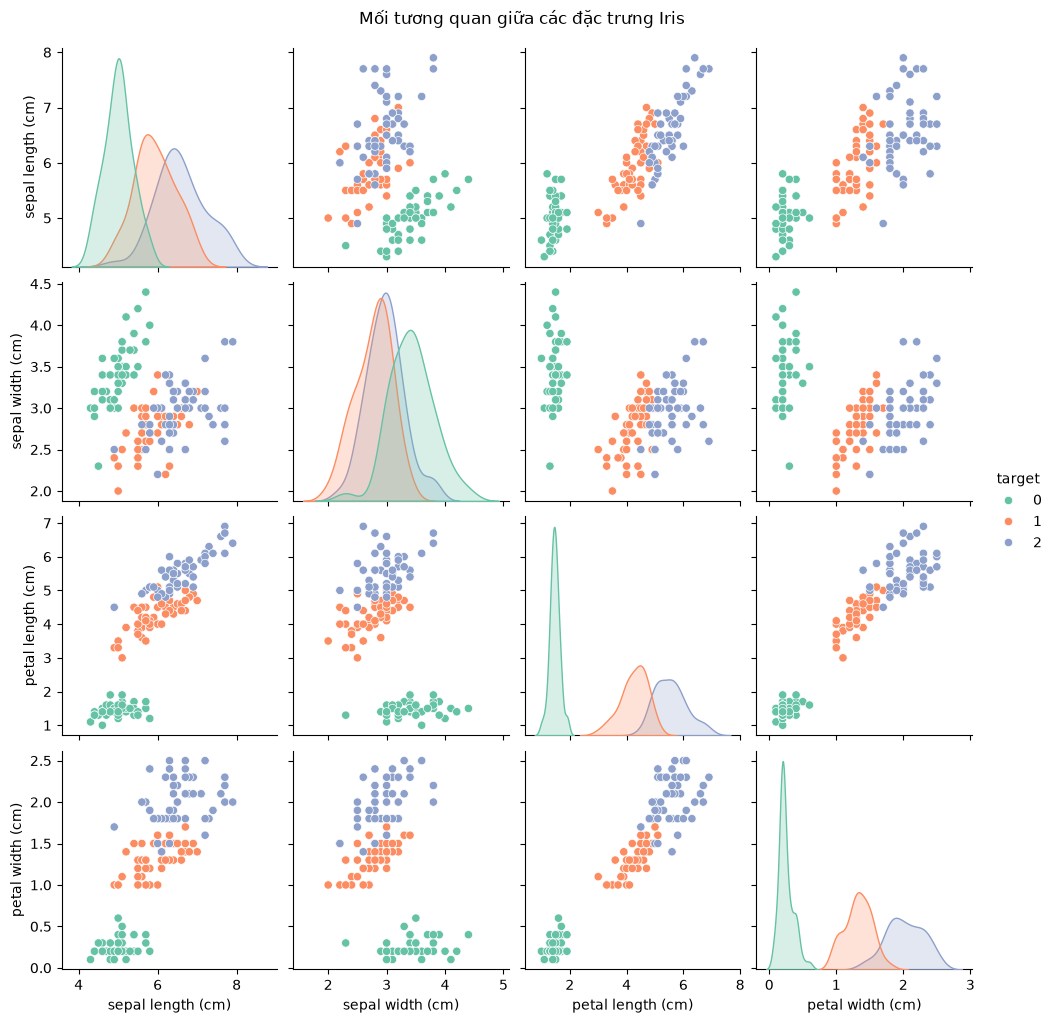

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,0.222222,0.625000,0.067797,0.041667,0
1,0.166667,0.416667,0.067797,0.041667,0
2,0.111111,0.500000,0.050847,0.041667,0
3,0.083333,0.458333,0.084746,0.041667,0
4,0.194444,0.666667,0.067797,0.041667,0


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler

BASE_DIR = Path().resolve().parent
OUTPUT_DIR = BASE_DIR / "output"

# 1. Nạp dữ liệu Iris từ sklearn
iris = load_iris(as_frame=True)
df_iris = iris.frame
features = iris.feature_names

print("Các đặc trưng (Features):", features)
print("Các lớp (Target Classes):", iris.target_names)
display(df_iris.head())

# 2. Trung bình và độ lệch chuẩn
summary_df = pd.DataFrame({
    'Mean': df_iris[features].mean(),
    'Std': df_iris[features].std()
})
print("\n--- Trung bình & Độ lệch chuẩn ---")
display(summary_df)

# 3. Biểu đồ Pairplot và lưu vào thư mục output
pair_plot = sns.pairplot(df_iris, hue='target', palette='Set2', diag_kind='kde')
pair_plot.fig.suptitle('Mối tương quan giữa các đặc trưng Iris', y=1.02)
pair_plot.savefig(OUTPUT_DIR / "iris_pairplot.png", dpi=300)
plt.show()

# 4. Chuẩn hóa về thang [0, 1] bằng MinMaxScaler
scaler = MinMaxScaler()
df_iris_scaled = df_iris.copy()
df_iris_scaled[features] = scaler.fit_transform(df_iris[features])

display(df_iris_scaled.head())